# Faster R-CNN — Detecção de Objetos (MILCO/NOMBO unificados em uma única classe)

Este notebook implementa um pipeline com **Faster R-CNN** (torchvision) para detectar o objeto de interesse em imagens de sonar, tratando **MILCO e NOMBO como uma única classe** ("objeto"), já que o objetivo aqui é apenas identificar a presença do objeto, independente do tipo.

Como o Faster R-CNN não trabalha com o formato de anotação do YOLO (caixas normalizadas `classe xc yc w h`), o notebook faz o seguinte:

1. **Converte** as anotações `.txt` no formato YOLO para uma classe única (mantém o formato YOLO, mas força `class_id = 0` em todas as linhas), salvando em uma pasta nova — os arquivos originais não são tocados;
2. No `Dataset`, converte essas anotações (normalizadas) para o formato absoluto `[xmin, ymin, xmax, ymax]` em pixels, exigido pelo torchvision;
3. Treina um **Faster R-CNN ResNet50-FPN v2** (pré-treinado na COCO) com 2 classes (fundo + objeto);
4. Lida com o desbalanceamento por sobreamostragem de imagens que contêm objeto;
5. Avalia com mAP (via `torchmetrics`) e visualiza as detecções.

> **Ajuste os caminhos na célula de configuração** conforme a estrutura real do seu dataset (a mesma gerada pelo `separacaoPastas.ipynb`: `images/train`, `labels/train`, etc.).

In [24]:
# Descomente se precisar instalar dependências no ambiente
# !pip install torch torchvision torchmetrics matplotlib pillow tqdm --quiet

In [25]:
import os
import random
from pathlib import Path

import torch
import torch.utils.data
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm.auto import tqdm

try:
    from torchmetrics.detection.mean_ap import MeanAveragePrecision
except ImportError:
    MeanAveragePrecision = None
    print("torchmetrics não encontrado. Instale com: pip install torchmetrics")

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

## 1. Configuração

Ajuste `BASE_DIR` e, se necessário, os nomes das subpastas para bater com a estrutura real do seu dataset.

In [26]:
# ==================== CONFIGURAÇÃO ====================
BASE_DIR = Path(r"D:\testte\SEPARACAO_MODELS\TESTES_COM_R_CNN_FASTER\dataset_yolo")  # pasta raiz com images/ e labels/

IMG_DIR = {
    "train": BASE_DIR / "images" / "train",
    "val":   BASE_DIR / "images" / "val",
    "test":  BASE_DIR / "images" / "test",
}
LABEL_DIR_YOLO = {
    "train": BASE_DIR / "labels" / "train",
    "val":   BASE_DIR / "labels" / "val",
    "test":  BASE_DIR / "labels" / "test",
}

# Pasta de saída com as anotações convertidas para classe única (não sobrescreve os originais)
LABEL_DIR_SINGLE = {
    split: BASE_DIR / "labels_single_class" / split for split in ["train", "val", "test"]
}

NUM_CLASSES = 2  # 0 = fundo (background), 1 = objeto (MILCO ou NOMBO, unificados)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 4
NUM_EPOCHS = 30
LR = 0.005
WEIGHT_DECAY = 0.0005
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

print(f"Device: {DEVICE}")

Device: cuda


## 1.1 Organizando o dataset (imagens + anotações em uma única pasta)

Se as imagens e os `.txt` do YOLO estão todos juntos em uma única pasta, a célula abaixo faz a divisão em `train`/`val`/`test` e organiza tudo na estrutura `images/<split>/` e `labels/<split>/` que o restante do notebook espera. Rode esta célula **antes** da conversão de anotações (seção 2).

In [27]:
# import shutil

# SOURCE_DIR = Path("dataset_raw")  # pasta única com imagens e anotações (.txt) juntas
# SPLIT_RATIOS = {"train": 0.7, "val": 0.2, "test": 0.1}  # deve somar 1.0
# COPY_FILES = True  # True = copia (mantém a pasta original intacta); False = move (shutil.move)

# img_exts = (".jpg", ".jpeg", ".png", ".bmp")
# img_paths = sorted([p for p in SOURCE_DIR.iterdir() if p.suffix.lower() in img_exts])
# random.shuffle(img_paths)

# n = len(img_paths)
# n_train = int(n * SPLIT_RATIOS["train"])
# n_val = int(n * SPLIT_RATIOS["val"])

# splits = {
#     "train": img_paths[:n_train],
#     "val": img_paths[n_train:n_train + n_val],
#     "test": img_paths[n_train + n_val:],
# }

# transfer = shutil.copy2 if COPY_FILES else shutil.move

# for split, paths in splits.items():
#     (BASE_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
#     (BASE_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)
#     for img_path in paths:
#         label_path = SOURCE_DIR / (img_path.stem + ".txt")
#         transfer(str(img_path), str(BASE_DIR / "images" / split / img_path.name))
#         if label_path.exists():
#             transfer(str(label_path), str(BASE_DIR / "labels" / split / label_path.name))
#         else:
#             # imagem sem anotação = sem objeto (exemplo de fundo); cria .txt vazio
#             (BASE_DIR / "labels" / split / label_path.name).touch()
#     print(f"{split}: {len(paths)} imagens")

# print(f"Total: {n} imagens organizadas em {BASE_DIR}/images e {BASE_DIR}/labels")

## 2. Conversão das anotações YOLO para classe única

O YOLO usa arquivos `.txt` por imagem com uma linha por objeto: `classe xc yc w h` (tudo normalizado 0–1). Como MILCO (classe 0) e NOMBO (classe 1) devem virar um único "objeto", a função abaixo reescreve cada linha trocando a classe original por `0`, mantendo as coordenadas. O resultado é salvo em `labels_single_class/`, preservando os `.txt` originais.

In [28]:
def convert_yolo_labels_to_single_class(src_dir: Path, dst_dir: Path):
    """
    Lê os .txt no formato YOLO (class xc yc w h, normalizados) e reescreve
    todas as linhas com class_id = 0, unificando MILCO e NOMBO em uma
    única classe "objeto". Imagens sem objeto geram um .txt vazio
    (mantido como exemplo de fundo/background).
    """
    dst_dir.mkdir(parents=True, exist_ok=True)
    n_files, n_boxes = 0, 0
    for txt_path in src_dir.glob("*.txt"):
        lines_out = []
        with open(txt_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                _, xc, yc, w, h = parts
                lines_out.append(f"0 {xc} {yc} {w} {h}")
                n_boxes += 1
        with open(dst_dir / txt_path.name, "w") as f:
            f.write("\n".join(lines_out))
        n_files += 1
    print(f"[{src_dir} -> {dst_dir}] {n_files} arquivos convertidos, {n_boxes} caixas (classe única).")

for split in ["train", "val", "test"]:
    if LABEL_DIR_YOLO[split].exists():
        convert_yolo_labels_to_single_class(LABEL_DIR_YOLO[split], LABEL_DIR_SINGLE[split])
    else:
        print(f"Aviso: pasta {LABEL_DIR_YOLO[split]} não encontrada, pulando split '{split}'.")

[D:\testte\SEPARACAO_MODELS\TESTES_COM_R_CNN_FASTER\dataset_yolo\labels\train -> D:\testte\SEPARACAO_MODELS\TESTES_COM_R_CNN_FASTER\dataset_yolo\labels_single_class\train] 819 arquivos convertidos, 484 caixas (classe única).
[D:\testte\SEPARACAO_MODELS\TESTES_COM_R_CNN_FASTER\dataset_yolo\labels\val -> D:\testte\SEPARACAO_MODELS\TESTES_COM_R_CNN_FASTER\dataset_yolo\labels_single_class\val] 234 arquivos convertidos, 116 caixas (classe única).
[D:\testte\SEPARACAO_MODELS\TESTES_COM_R_CNN_FASTER\dataset_yolo\labels\test -> D:\testte\SEPARACAO_MODELS\TESTES_COM_R_CNN_FASTER\dataset_yolo\labels_single_class\test] 117 arquivos convertidos, 68 caixas (classe única).


## 3. Dataset

O torchvision espera, para cada imagem, um dicionário `target` com `boxes` no formato absoluto `[xmin, ymin, xmax, ymax]` (em pixels) e `labels` (inteiros, sendo `0` reservado para o fundo). A classe abaixo lê as anotações já convertidas e faz essa transformação a partir das coordenadas normalizadas do YOLO.

In [29]:
class SonarDetectionDataset(torch.utils.data.Dataset):
    """
    Dataset para Faster R-CNN a partir de imagens + anotações YOLO
    (já convertidas para classe única). Converte bounding boxes
    normalizadas (xc, yc, w, h) para o formato absoluto exigido pelo
    torchvision: [xmin, ymin, xmax, ymax] em pixels.
    """
    def __init__(self, img_dir: Path, label_dir: Path, transforms=None):
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.transforms = transforms
        exts = ("*.jpg", "*.jpeg", "*.png", "*.bmp")
        self.img_paths = sorted(sum([list(img_dir.glob(e)) for e in exts], []))

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        img = Image.open(img_path).convert("RGB")
        w_img, h_img = img.size

        label_path = self.label_dir / (img_path.stem + ".txt")
        boxes, labels = [], []
        if label_path.exists():
            with open(label_path, "r") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue
                    _, xc, yc, w, h = map(float, parts)
                    xc, yc, w, h = xc * w_img, yc * h_img, w * w_img, h * h_img
                    xmin, ymin = xc - w / 2, yc - h / 2
                    xmax, ymax = xc + w / 2, yc + h / 2
                    xmin, ymin = max(0.0, xmin), max(0.0, ymin)
                    xmax, ymax = min(float(w_img), xmax), min(float(h_img), ymax)
                    if xmax > xmin and ymax > ymin:
                        boxes.append([xmin, ymin, xmax, ymax])
                        labels.append(1)  # classe única "objeto"

        boxes = torch.as_tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0, 4), dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0]) if len(boxes) else torch.zeros((0,))
        iscrowd = torch.zeros((len(boxes),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
            "area": area,
            "iscrowd": iscrowd,
        }

        img_tensor = torchvision.transforms.functional.to_tensor(img)

        if self.transforms:
            img_tensor, target = self.transforms(img_tensor, target)

        return img_tensor, target


def collate_fn(batch):
    return tuple(zip(*batch))

## 4. Transformações / augmentation

Em sonar de varredura lateral, a sombra acústica do objeto depende da direção across-track (altura da imagem). Por isso, seguindo a mesma restrição já usada no pipeline YOLO deste projeto, evitamos **flip vertical e rotação livre** — apenas o flip horizontal (eixo along-track) é aplicado como augmentation.

In [30]:
class RandomHorizontalFlipWithBoxes:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, img, target):
        if random.random() < self.p:
            img = img.flip(-1)
            w = img.shape[-1]
            boxes = target["boxes"].clone()
            if len(boxes):
                boxes[:, [0, 2]] = w - boxes[:, [2, 0]]
            target["boxes"] = boxes
        return img, target


class ComposeTransforms:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img, target):
        for t in self.transforms:
            img, target = t(img, target)
        return img, target


def get_transform(train: bool):
    transforms = []
    if train:
        transforms.append(RandomHorizontalFlipWithBoxes(0.5))
    return ComposeTransforms(transforms)

## 5. Datasets, DataLoaders e desbalanceamento

O dataset é desbalanceado principalmente entre **imagens com objeto x imagens de fundo** (a distinção MILCO/NOMBO deixou de existir após a unificação de classes). Para compensar, usamos um `WeightedRandomSampler` que sobreamostra as imagens com objeto durante o treino.

In [31]:
train_dataset = SonarDetectionDataset(IMG_DIR["train"], LABEL_DIR_SINGLE["train"], transforms=get_transform(train=True))
val_dataset   = SonarDetectionDataset(IMG_DIR["val"],   LABEL_DIR_SINGLE["val"],   transforms=get_transform(train=False))
test_dataset  = SonarDetectionDataset(IMG_DIR["test"],  LABEL_DIR_SINGLE["test"],  transforms=get_transform(train=False))

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

def has_object(dataset, idx):
    label_path = dataset.label_dir / (dataset.img_paths[idx].stem + ".txt")
    if not label_path.exists():
        return False
    with open(label_path) as f:
        return any(line.strip() for line in f)

sample_weights = [3.0 if has_object(train_dataset, i) else 1.0 for i in range(len(train_dataset))]
sampler = torch.utils.data.WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
    collate_fn=collate_fn, num_workers=0,
)
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=collate_fn, num_workers=0,
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=collate_fn, num_workers=0,
)

Train: 819 | Val: 234 | Test: 117


## 6. Modelo

Faster R-CNN ResNet50-FPN v2 pré-treinado na COCO, com a cabeça de classificação (`box_predictor`) trocada para `NUM_CLASSES = 2` (fundo + objeto).

In [32]:
def build_model(num_classes: int):
    weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    model = fasterrcnn_resnet50_fpn_v2(weights=weights)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

model = build_model(NUM_CLASSES).to(DEVICE)

## 7. Funções de treino e avaliação

In [33]:
def train_one_epoch(model, optimizer, data_loader, device, epoch):
    model.train()
    total_loss = 0.0
    loop = tqdm(data_loader, desc=f"Época {epoch}")
    for images, targets in loop:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    return total_loss / len(data_loader)


@torch.no_grad()
def evaluate_map(model, data_loader, device):
    if MeanAveragePrecision is None:
        print("torchmetrics indisponível — pulando cálculo de mAP.")
        return None
    model.eval()
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    for images, targets in tqdm(data_loader, desc="Avaliando"):
        images = [img.to(device) for img in images]
        preds = model(images)
        preds = [{k: v.cpu() for k, v in p.items()} for p in preds]
        targets_cpu = [{k: v.cpu() for k, v in t.items()} for t in targets]
        metric.update(preds, targets_cpu)
    return metric.compute()

## 8. Loop de treinamento

In [34]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=WEIGHT_DECAY)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

best_map = 0.0
history = {"train_loss": [], "val_map": []}

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = train_one_epoch(model, optimizer, train_loader, DEVICE, epoch)
    lr_scheduler.step()
    history["train_loss"].append(train_loss)

    val_result = evaluate_map(model, val_loader, DEVICE)
    val_map = val_result["map"].item() if val_result else 0.0
    val_map50 = val_result["map_50"].item() if val_result else 0.0
    history["val_map"].append(val_map)

    print(f"Época {epoch}: loss={train_loss:.4f} | mAP={val_map:.4f} | mAP50={val_map50:.4f}")

    if val_map > best_map:
        best_map = val_map
        torch.save(model.state_dict(), CHECKPOINT_DIR / "fasterrcnn_melhor.pth")
        print(f"  -> Novo melhor modelo salvo (mAP={best_map:.4f})")

torch.save(model.state_dict(), CHECKPOINT_DIR / "fasterrcnn_final.pth")

Avaliando: 100%|██████████| 59/59 [00:32<00:00,  1.82it/s]


Época 1: loss=0.1463 | mAP=0.1580 | mAP50=0.4228
  -> Novo melhor modelo salvo (mAP=0.1580)


Avaliando: 100%|██████████| 59/59 [00:30<00:00,  1.92it/s]


Época 2: loss=0.1300 | mAP=0.2003 | mAP50=0.5054
  -> Novo melhor modelo salvo (mAP=0.2003)


Avaliando: 100%|██████████| 59/59 [00:30<00:00,  1.91it/s]


...

Época 28: loss=0.0199 | mAP=0.3436 | mAP50=0.6372


Avaliando: 100%|██████████| 59/59 [00:30<00:00,  1.92it/s]


Época 29: loss=0.0235 | mAP=0.3382 | mAP50=0.6328


Avaliando: 100%|██████████| 59/59 [00:30<00:00,  1.92it/s]


Época 30: loss=0.0229 | mAP=0.3459 | mAP50=0.6511


## 9. Curvas de treino

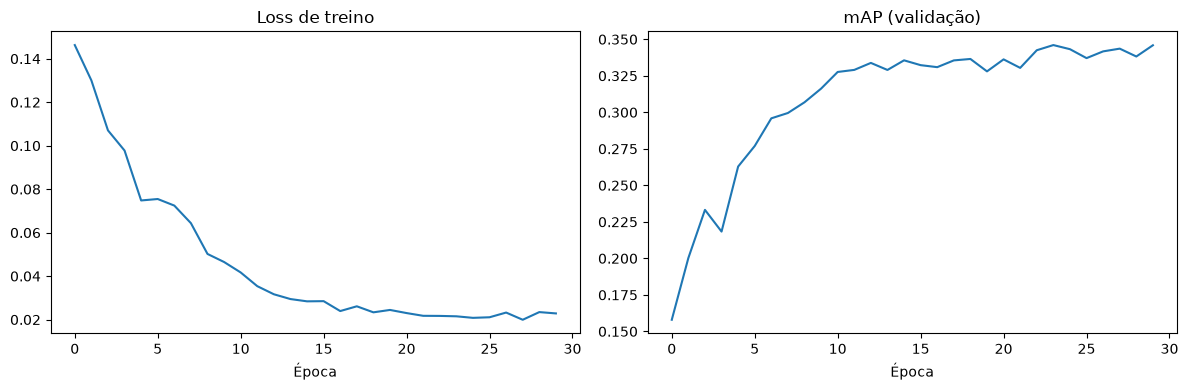

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"])
axes[0].set_title("Loss de treino")
axes[0].set_xlabel("Época")

axes[1].plot(history["val_map"])
axes[1].set_title("mAP (validação)")
axes[1].set_xlabel("Época")
plt.tight_layout()
plt.show()

## 10. Avaliação final no conjunto de teste

In [36]:
model.load_state_dict(torch.load(CHECKPOINT_DIR / "fasterrcnn_melhor.pth"))
test_result = evaluate_map(model, test_loader, DEVICE)
if test_result:
    print(f"Teste — mAP: {test_result['map'].item():.4f} | mAP50: {test_result['map_50'].item():.4f} "
          f"| mAP75: {test_result['map_75'].item():.4f} | Recall (mar_100): {test_result['mar_100'].item():.4f}")

Avaliando: 100%|██████████| 30/30 [00:15<00:00,  1.88it/s]

Teste — mAP: 0.4083 | mAP50: 0.7483 | mAP75: 0.3946 | Recall (mar_100): 0.5250


## 11. Visualização das detecções

Verde = ground truth, vermelho = predição do modelo (acima do limiar de confiança).

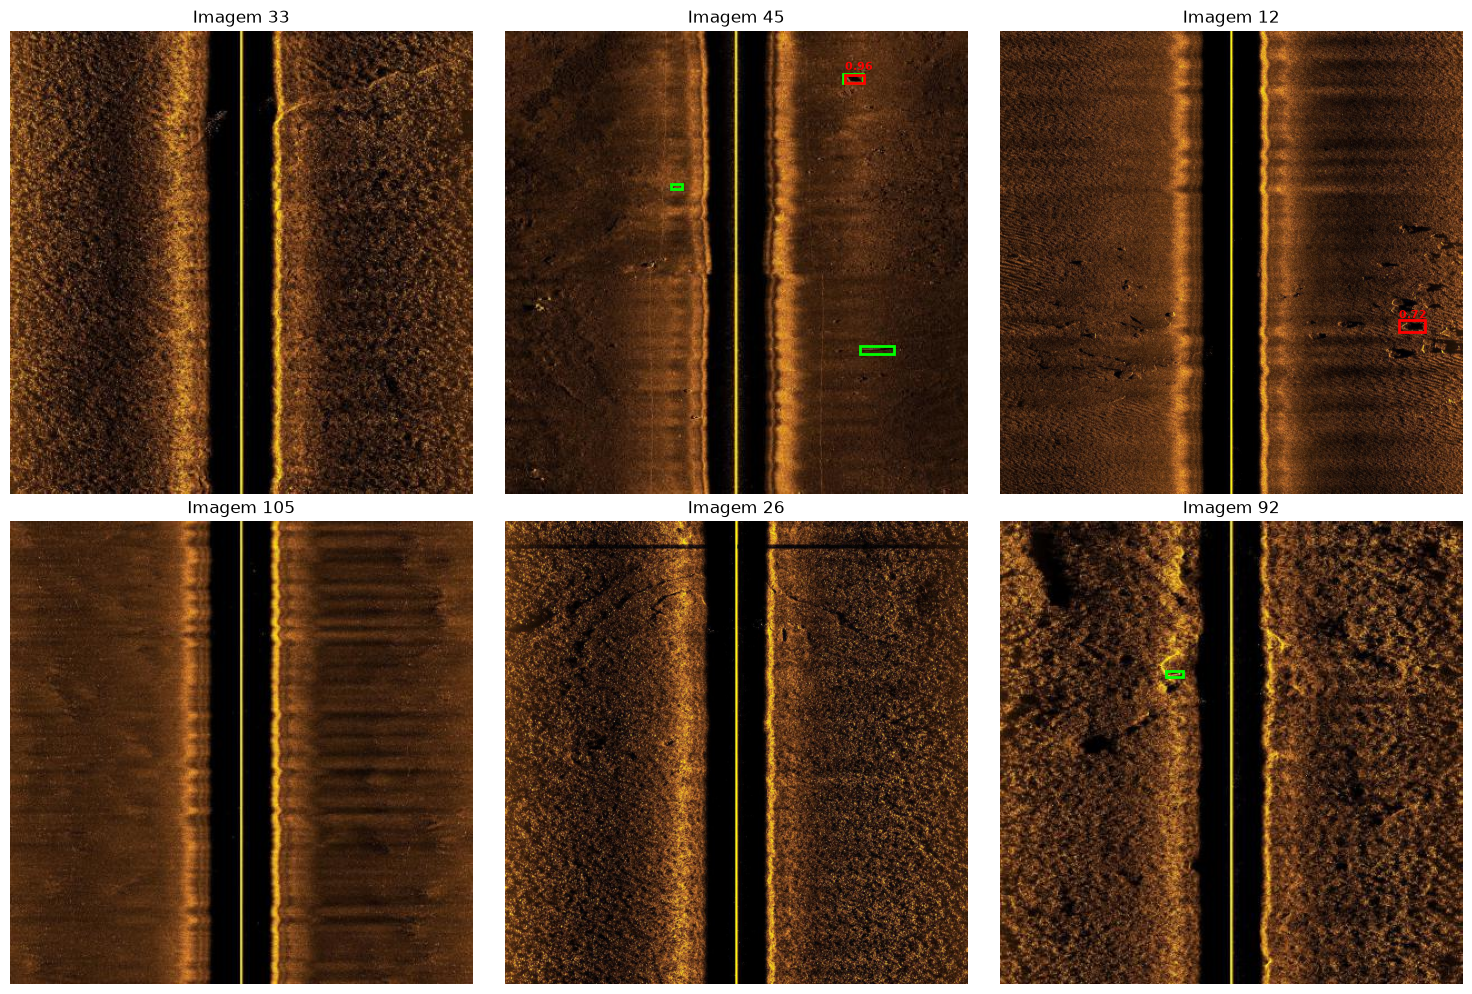

In [37]:
@torch.no_grad()
def visualize_predictions(model, dataset, device, num_images=6, score_threshold=0.5):
    model.eval()
    indices = random.sample(range(len(dataset)), min(num_images, len(dataset)))
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()

    for ax, idx in zip(axes, indices):
        img, target = dataset[idx]
        pred = model([img.to(device)])[0]

        img_np = img.permute(1, 2, 0).cpu().numpy()
        ax.imshow(img_np)

        for box in target["boxes"]:
            x1, y1, x2, y2 = box.tolist()
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                            linewidth=2, edgecolor="lime", facecolor="none"))

        for box, score in zip(pred["boxes"].cpu(), pred["scores"].cpu()):
            if score >= score_threshold:
                x1, y1, x2, y2 = box.tolist()
                ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                                linewidth=2, edgecolor="red", facecolor="none"))
                ax.text(x1, max(y1 - 5, 0), f"{score:.2f}", color="red", fontsize=8, weight="bold")

        ax.set_title(f"Imagem {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(model, test_dataset, DEVICE)

## Observações

- O modelo trata **qualquer objeto (MILCO ou NOMBO) como uma única classe** ("objeto") — a distinção entre os dois tipos é descartada, conforme pedido.
- As anotações originais em `labels/` (formato YOLO) **não são alteradas**; a conversão gera uma cópia em `labels_single_class/` com `class_id = 0` em todas as caixas.
- Ajuste `BATCH_SIZE`, `NUM_EPOCHS` e o `score_threshold` da visualização conforme a VRAM disponível e os resultados observados.
- Para comparar com o pipeline YOLO já treinado neste projeto (mAP50≈0.51, recall≈0.47), use as mesmas métricas (`map_50`, `mar_100`) aqui, calculadas no mesmo split de teste.